# Notebook 5: Simulating population dynamics
## 5.0) Setup of the population dynamics problem
Population dynamics asks: given individuals that are born, reproduce, interact and die, how does the population number and their spatial distribution change over time. Just like in thermodynamics, instead of looking at each individual member of the species, you look at the macroscopic variables.

https://www.khanacademy.org/test-prep/mcat/society-and-culture/demographics/v/population-dynamics
https://www.darwininitiative.org.uk/documents/DAR15002/43/15-002%20Presentation%20Population%20Dynamics.pdf

Andersson & Britton, Stochastic Epidemic Models and Their Statistical Analysis (2000); Diekmann, Heesterbeek & Britton, Mathematical Tools for Understanding Infectious Disease Dynamics (2013)

Haccou, Jagers & Vatutin, Branching Processes: Variation, Growth, and Extinction of Populations (2005)

Lockwood, Cassey & Blackburn, “The role of propagule pressure in explaining species invasions”, TREE 20 (2005)

In [16]:
import numpy as np
import matplotlib.pyplot as plt

from Functions_final import distance_cells      
from Functions_final import final_history        
from Functions_final import kappa_exact     

## 5.1) How the problem will be described

So far every run is a single cascade: armed traps fire, become spent, and never come back. The cascade consumes its own resource and always dies, so the model can only answer two questions: does a cascade invade ($\rho\kappa > 1$), and how much does it fire in total ($F = 1 - e^{-\rho\kappa F}$).

This is a special case of a population model. A fired trap is an individual that reproduces by firing others, uses up a finite resource (armed traps), and then dies (becomes spent). Each state of the lattice has a population reading:

| State | Mousetrap | Population |
|---|---|---|
| $-1$ | inert cell | unsuitable habitat / immune individual |
| $0$ | armed | susceptible / empty patch that can be colonised |
| $1$ | firing | infected / occupied, reproducing patch |
| $-2$ | spent | recovered / dead / extinct patch |

The model parameters translate in the same way:
- $\kappa$ is the offspring per individual per generation.
- $\rho\kappa$ plays the role of $R_0$.
- $f_k$ and $p_{\text{long}}$ form the dispersal kernel.
- $F = 1 - e^{-\rho\kappa F}$ is the Kermack–McKendrick final-size equation of the SIR epidemic.

What the model lacks is **renewal**. In real populations, births, recolonisation or waning immunity replace what is used up. I add one parameter, $p_{\text{regen}}$: the probability per generation that a spent trap is re-armed ($-2 \to 0$). With it the lattice becomes a spatial SIRS model, and the questions change from *"how big is the cascade?"* to the standard questions of population dynamics:

1. **Invasion:** does a small seed grow? (threshold $\rho\kappa > 1$, unchanged)
2. **Long-term state:** does the population settle at an equilibrium, oscillate, or go extinct?
3. **Regulation:** at equilibrium the armed density should settle near $S^* \approx 1/\kappa$, the level at which each firing trap exactly replaces itself.
4. **Stochastic extinction:** on a finite lattice a population that mean-field theory says should persist can die out by chance.

Each question is answered twice: by the lattice simulation, and by a mean-field map that extends the Poisson argument of Notebook 3:

$$
\begin{aligned}
\text{new}_t &= s_t\left(1 - e^{-\kappa i_t}\right) \\
s_{t+1} &= s_t - \text{new}_t + p_{\text{regen}}\, r_t \\
i_{t+1} &= \text{new}_t \\
r_{t+1} &= r_t + i_t - p_{\text{regen}}\, r_t
\end{aligned}
$$

Here $s, i, r$ are the fractions of the lattice that are armed, firing and spent, with $s + i + r = \rho$. Setting $p_{\text{regen}} = 0$ recovers the original model, which is the first consistency check.

The problem will be second dimensional, since it is more resemblant of real-life population dynamics and it has been shown that mean-field theory works best in that dimension.

# 5.2) Adding the probability of regeneration
We can redefine the history function to incorporate the new state, -2, and add a probability of regeneration:

In [17]:
def regen_history(rho, f_k, p_succ_long, p_succ_short=0.9,
                  p_long=0.5, m=1, p_regen=0.0, L=50, steps=300, rng=None): # Setting the probabiloty of regeneration to zero 
                                                                            # returns the original model
    rng = rng or np.random.default_rng()
    state = np.where(rng.random((L, L)) < rho, 0, -1)
    ys, xs = np.where(state == 0)
    if len(xs) == 0:
        return [state.copy()]
    seed = rng.integers(len(xs))
    state[ys[seed], xs[seed]] = 1
    snapshots = [state.copy()]

    for t in range(steps):
        fired = np.argwhere(state == 1)
        if len(fired) == 0:
            break
        new_fires = []
        for fy, fx in fired:
            for _ in range(m):
                if rng.random() < p_long:
                    k = f_k(rng)
                    if k < 2:
                        continue
                    p_hit = p_succ_long(k)
                else:
                    k, p_hit = 1, p_succ_short
                candidates = distance_cells(fy, fx, k, L)
                if not candidates:
                    continue
                ty, tx = candidates[rng.integers(len(candidates))]
                if state[ty, tx] == 0 and rng.random() < p_hit:
                    new_fires.append((ty, tx))

        regen = (state == -2) & (rng.random((L, L)) < p_regen)   # NEW
        state[state == 1] = -2
        state[regen] = 0                                          # NEW

        if not new_fires:
            snapshots.append(state.copy())
            break
        for ty, tx in set(new_fires):
            state[ty, tx] = 1
        snapshots.append(state.copy())

    return snapshots

## 5.3) Invasion: Does a small seed grow or die out

The first question of any population model is whether a few individuals introduced into fresh habitat establish themselves. Early on almost every armed trap is still armed, so re-arming plays no role. Invasion depends only on the first generations, and $p_{\text{regen}}$ is irrelevant here.

**Threshold.** Each firing trap makes $m$ attempts. Each attempt hits an armed trap with probability $\rho\,\bar q$, where $\bar q = \kappa/m$. The mean number of offspring is therefore
$$R_0 = \rho\kappa .$$
If $R_0 < 1$ the seed dies with certainty. If $R_0 > 1$ it *can* invade, but it is not guaranteed to.

**Invasion probability.** Treat the early cascade as a Galton–Watson branching process. If attempts never hit the same trap twice, the number of offspring is $\text{Binomial}(m, \rho\kappa/m)$. Let $q$ be the probability that the seed's lineage survives forever. The seed's lineage dies only if every child's lineage dies, so
$$1 - q = \left(1 - \frac{\rho\kappa}{m}\,q\right)^{m}.$$
As $m \to \infty$ the offspring become Poisson, and this becomes
$$q = 1 - e^{-\rho\kappa q},$$
which is **the same equation as the final-size equation** $F = 1 - e^{-\rho\kappa F}$. The probability that one seed invades equals the fraction of the population an invasion eventually reaches.

**Measurement.** For each $\rho$, run many single-seed simulations. A run counts as "invaded" if it fires at least $n_c = 50$ traps, or if it is still active after 15 generations. The fraction of invaded runs estimates $q(\rho)$.

The theoretical part of this section is computed in the following cells:

In [18]:
# --- supercritical parameter set (Notebook 3, section 3.9) ---
f_k          = lambda rng: rng.geometric(p=0.3) + 1
p_succ_long  = lambda k: 0.9 + 0 * np.asarray(k, float)
p_succ_short = 0.9
p_long, m    = 1.0, 5

Kmax  = 400
k_arr = np.arange(1, Kmax + 1)
pk    = np.where(k_arr >= 2, 0.3 * 0.7**(k_arr - 2), 0.0)
kappa = kappa_exact(pk, p_succ_long, p_succ_short, p_long, m)[0]
print(f"kappa = {kappa:.3f}   rho_onset = {1/kappa:.3f}")  

kappa = 4.500   rho_onset = 0.222


In [19]:
from scipy.optimize import brentq

def q_invade(R, m=None):
    """Branching-process survival probability. m=None -> Poisson limit."""
    if R <= 1:
        return 0.0
    if m is None:
        g = lambda q: q - (1 - np.exp(-R * q))
    else:
        g = lambda q: q - (1 - (1 - R * q / m) ** m)
    return brentq(g, 1e-9, 1)

The actual numericla simulation though, is the following:

In [20]:
def invaded(history, n_c=50, t_c=15):
    last = history[-1]
    fired_total = np.sum(last == -2) + np.sum(last == 1)
    still_active = len(history) > t_c and np.sum(last == 1) > 0
    return fired_total >= n_c or still_active

rho_vals = np.array([0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7])
n_runs = 200
rng = np.random.default_rng(1)

p_sim, p_err = [], []
for rho in rho_vals:
    x = [invaded(regen_history(rho, f_k, p_succ_long, p_long=p_long, m=m,
                               p_regen=0.05, L=50, steps=15, rng=rng))
         for _ in range(n_runs)]
    p = np.mean(x)
    p_sim.append(p)
    p_err.append(np.sqrt(p * (1 - p) / n_runs)) # took me over a minute

Let us now plot both the computed and theoretical values and see if they match as expected:

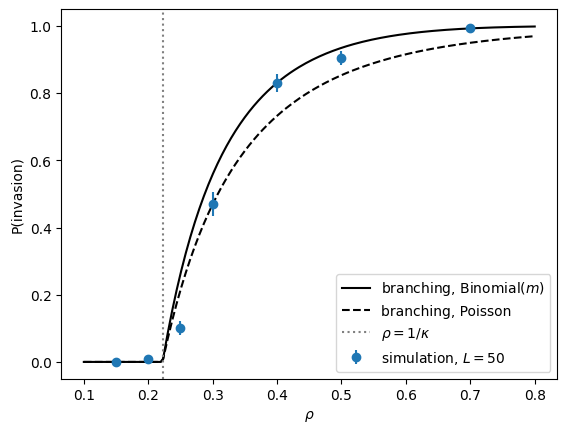

In [21]:
rr = np.linspace(0.1, 0.8, 200)
plt.plot(rr, [q_invade(r * kappa, m) for r in rr], 'k-',  label='branching, Binomial($m$)')
plt.plot(rr, [q_invade(r * kappa)    for r in rr], 'k--', label='branching, Poisson')
plt.errorbar(rho_vals, p_sim, yerr=p_err, fmt='o', label='simulation, $L=50$')
plt.axvline(1 / kappa, color='grey', ls=':', label=r'$\rho = 1/\kappa$')
plt.xlabel(r'$\rho$'); plt.ylabel('P(invasion)')
plt.savefig("image")
plt.legend(); plt.show() 

This plot makes the following three things real:
1. The threshold is real.
Below ρ = 1/κ ≈ 0.22, invasion essentially never happens. Above it, P(invasion) rises steeply from zero, with a kink at the threshold, which is the signature of a transcritical bifurcation. The R₀ = ρκ criterion holds.

2. Above the threshold, invasion is still not guaranteed.
At ρ = 0.3, R₀ = 1.35 so the population should grow on average, yet about half of single introductions die out. This is demographic stochasticity: one founder can have zero offspring by chance before the lineage takes off. It is importamt to mention that mean-field theory says “R₀ > 1 means it grows” and misses this entirely. In invasion biology this is called propagule pressure: with n independent seeds the chance of success is 1 − (1−q)ⁿ, so at ρ = 0.3 five seeds give about 97%. 

3. Binomial beats Poisson because of offspring variance.
Near the threshold, q ≈ 2(R₀ − 1)/σ², where σ² is the variance in offspring number. A trap has at most m = 5 attempts, so its offspring count is Binomial with σ² = R₀(1 − R₀/m), which is less than the Poisson σ² = R₀. Lower variance means fewer unlucky early extinctions, so the probability is higher. The simulation follows the Binomial curve for ρ ≥ 0.4. The fact that the point at 0.3 sits on the Poisson curve should be a coincidence, not an agreement or proof that poisson distribution has a lower invariance.

4. Near the threshold the simulation falls below both curves.
At ρ = 0.25 the theory gives 0.26 and the simulation gives 0.10. The following is beleived to be the reason: Near R₀ = 1, q depends very steeply on R₀, so a small loss of offspring matters a lot. Using the approximation above, a simulated value of 0.10 corresponds to R₀,eff ≈ 1.04 rather than 1.125, which is about 7% fewer effective offspring per firing. The cause is locality: attempts collide on the same target, or land on the trap that fired the parent, which is already spent. This is the same mechanism behind the +0.10 onset shift in Notebook 3 and the κ_eff < κ result in the README. Over the first few generations it amounts to an apparent threshold slightly above 1/κ, roughly 0.23–0.24 in the plot.

5. The ρ = 0.2 point (0.01) is an artifact of the criterion.
At R₀ = 0.9 a subcritical cascade has mean total size 1/(1 − R₀) = 10 traps but a long tail, so about 1% of runs reach n_c = 50 and get counted as “invaded” even though they die later. Raising n_c or t_c would push this point to zero.

A summary of this section is the following:
R₀ = ρκ sets whether invasion is possible. The branching-process q sets how likely it is, with the Binomial form preferred because m is small. Spatial locality lowers the effective R₀ near the threshold and shifts it slightly upward.

## 5.4) **Long-term state:** does the population settle at an equilibrium, oscillate, or go extinct?

Once a seed has invaded, the long-term behaviour depends on the re-arming rate $p_{\text{regen}}$.

**Mean-field fixed point.** Write $s, i, r$ for the fractions of the lattice that are armed, firing and spent. A stationary state of the map in 5.1 must satisfy
$$
i^* = s^*\left(1 - e^{-\kappa i^*}\right), \qquad r^* = \frac{i^*}{p_{\text{regen}}}, \qquad s^* + i^* + r^* = \rho .
$$
The first condition says each firing trap exactly replaces itself. For small $i^*$, $1 - e^{-\kappa i^*} \approx \kappa i^*$, so
$$
s^* \approx \frac{1}{\kappa}, \qquad i^* \approx \frac{p_{\text{regen}}}{1 + p_{\text{regen}}}\left(\rho - \frac{1}{\kappa}\right).
$$
So the population **regulates its own resource**. It eats the armed traps down to the replacement level $1/\kappa$, which is the same number as the invasion threshold, whatever $\rho$ is. Increasing $\rho$ raises $i^*$, not $s^*$. In ecology this is the "$R^* $ rule"; in epidemiology it is the statement that the endemic susceptible fraction is $1/R_0$.

**Stability and oscillations.** Linearise the map about $(s^*, i^*)$, eliminating $r = \rho - s - i$. The Jacobian has a complex-conjugate pair of eigenvalues $\lambda$, and $|\lambda| < 1$. Deviations therefore decay as $|\lambda|^t$ and oscillate with period $T = 2\pi / |\arg\lambda|$. These are **damped boom–bust cycles**: armed traps build up, an outbreak follows, armed traps are depleted, the outbreak collapses, and the cycle repeats.

**Burnout.** The first outbreak overshoots: it consumes far more armed traps than the equilibrium needs, and $i$ then crashes to a deep minimum. Mean-field has no trouble with this, because $i$ is continuous and never reaches zero. On a lattice the population is a whole number of traps. If the minimum of the mean-field $i$ corresponds to fewer than about one trap, the population goes extinct in that first trough. The prediction is that persistence is controlled by **the number of firing traps at the first trough**, $L^2\, i_{\min}$, not just by $\rho\kappa > 1$.

**Possible outcomes for a single run:**
1. Early extinction: the seed fails to invade (section 5.3).
2. Burnout: it invades, then dies in the first trough.
3. Persistence: damped oscillations settle at the endemic state $(s^*, i^*)$.

In [22]:
from scipy.optimize import brentq

rho_lt = 0.8

def fixed_point(rho, kappa, p_regen):
    g = lambda i: i / (1 - np.exp(-kappa * i)) + i * (1 + 1 / p_regen) - rho
    i = brentq(g, 1e-12, rho)
    s = i / (1 - np.exp(-kappa * i))
    return s, i, i / p_regen

def jacobian_eigs(rho, kappa, p_regen):
    s, i, r = fixed_point(rho, kappa, p_regen)
    e = np.exp(-kappa * i)
    J = np.array([[e - p_regen,  -s * kappa * e - p_regen],
                  [1 - e,         s * kappa * e]])
    return np.linalg.eigvals(J)

In [23]:
def classify_run(history, t_burn=100, t_early=8):
    """Label one run and return the diagnostics."""
    i = np.array([np.sum(s == 1) for s in history]) / history[0].size
    T = len(i) - 1
    if i[-1] == 0:
        return dict(label='early extinction' if T < t_early else 'burnout', t_ext=T)
    if T <= t_burn + 20:
        raise ValueError("run too short: increase steps")

    x = i[t_burn:] - i[t_burn:].mean()
    acf = np.correlate(x, x, 'full')[len(x) - 1:]
    acf /= acf[0]
    freqs = np.fft.rfftfreq(len(x))
    power = np.abs(np.fft.rfft(x)) ** 2
    k = np.argmax(power[1:]) + 1
    half = len(x) // 2

    return dict(label='persist',
                mean_i=i[t_burn:].mean(),
                std_i=x.std(),
                amp_ratio=x[half:].std() / x[:half].std(),   # ~1 -> stationary
                acf_min=acf[1:40].min(),                     # < 0 -> oscillatory
                period=1 / freqs[k])                         # compare with mean-field

L=30  std(i)=0.0120  std*L=0.359  period=13.6  acf_min=-0.47  amp_ratio=0.91
L=50  std(i)=0.0076  std*L=0.381  period=13.1  acf_min=-0.55  amp_ratio=0.95
L=80  std(i)=0.0045  std*L=0.356  period=12.8  acf_min=-0.53  amp_ratio=1.17
mean-field: |lambda|=0.907  period=12.5


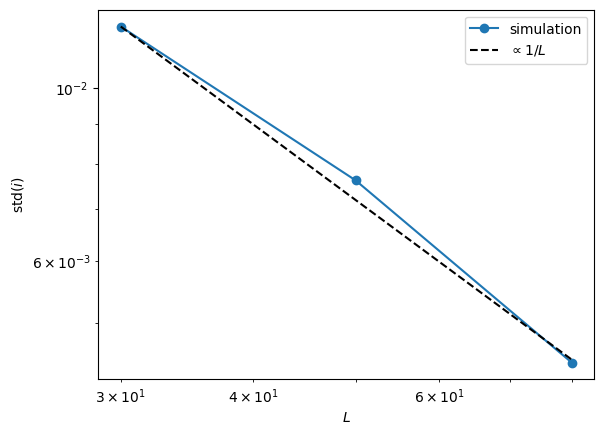

In [24]:
# Scaling test: limit cycle vs noise-driven quasi-cycles
L_vals, n_rep, p_test = (30, 50, 80), 3, 0.1
rng = np.random.default_rng(5)
amp = {}
for L in L_vals:
    res = []
    while len(res) < n_rep:
        h = regen_history(rho_lt, f_k, p_succ_long, p_long=p_long, m=m,
                          p_regen=p_test, L=L, steps=400, rng=rng)
        r = classify_run(h)
        if r['label'] == 'persist':
            res.append(r)
    amp[L] = np.mean([r['std_i'] for r in res])
    print(f"L={L}  std(i)={amp[L]:.4f}  std*L={amp[L]*L:.3f}  "
          f"period={np.mean([r['period'] for r in res]):.1f}  "
          f"acf_min={np.mean([r['acf_min'] for r in res]):.2f}  "
          f"amp_ratio={np.mean([r['amp_ratio'] for r in res]):.2f}")

lam = jacobian_eigs(rho_lt, kappa, p_test)[0]
print(f"mean-field: |lambda|={abs(lam):.3f}  period={2*np.pi/abs(np.angle(lam)):.1f}")

fig, ax = plt.subplots()
ax.loglog(L_vals, [amp[L] for L in L_vals], 'o-', label='simulation')
ax.loglog(L_vals, amp[L_vals[0]] * L_vals[0] / np.array(L_vals), 'k--', label=r'$\propto 1/L$')
ax.set_xlabel('$L$'); ax.set_ylabel(r'std$(i)$'); ax.legend()
fig.savefig("image2.png", dpi=200, bbox_inches='tight')   # save BEFORE show
plt.show()

**Result.** The measured amplitude falls as $L$ increases and lies close to the $L^{-1}$ reference line. This matches the quasi-cycle prediction: the oscillation is sustained by finite-size demographic noise and should vanish as $L \to \infty$. It is not a deterministic limit cycle.

Although it looks initially promising, it can be improved in two distinct ways:

- **The reference line is not a fit.** The dashed line $\propto 1/L$ is drawn through the $L = 30$ point by construction, so the agreement there is automatic. Only the positions of the $L = 50$ and $L = 80$ points relative to the line carry information. The small excess at $L = 50$ is within the run-to-run scatter of 3 runs.
- **There are no error bars.** Each point is the mean of only 3 surviving runs, and three such points cannot distinguish a slope of $-1$ from, say, $-0.8$. The plot is *consistent with* $L^{-1}$ but does not yet *measure* the exponent.

To turn this into a measurement, the next cell stores the amplitude of every run, adds standard-error bars, and fits the exponent directly by weighted least squares in log–log space.

In [25]:
L_vals, n_rep, p_test = (30, 50, 80), 3, 0.1
rng = np.random.default_rng(5)
amp, amp_runs = {}, {}                                
for L in L_vals:
    res = []
    while len(res) < n_rep:
        h = regen_history(rho_lt, f_k, p_succ_long, p_long=p_long, m=m,
                          p_regen=p_test, L=L, steps=400, rng=rng)
        r = classify_run(h)
        if r['label'] == 'persist':
            res.append(r)
    amp_runs[L] = [r['std_i'] for r in res]             
    amp[L] = np.mean(amp_runs[L])
    print(f"L={L}  std(i)={amp[L]:.4f}  std*L={amp[L]*L:.3f}")

L=30  std(i)=0.0120  std*L=0.359
L=50  std(i)=0.0076  std*L=0.381
L=80  std(i)=0.0045  std*L=0.356


slope = -1.00 ± 0.13   (quasi-cycles: -1, limit cycle: 0)


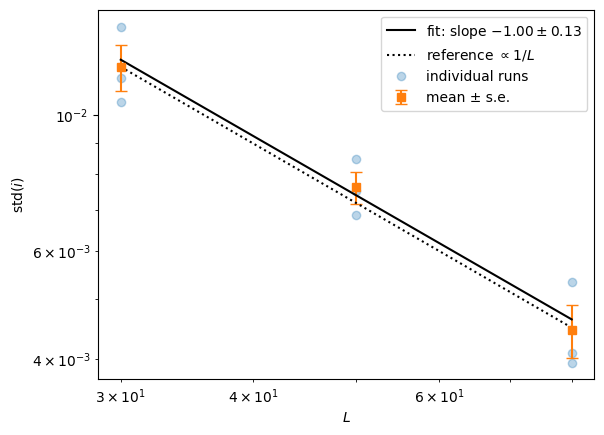

In [26]:
Ls = np.array(L_vals, float)
mu = np.array([np.mean(amp_runs[L]) for L in L_vals])
se = np.array([np.std(amp_runs[L], ddof=1) / np.sqrt(len(amp_runs[L])) for L in L_vals])

# weighted fit: log std = a + b log L
(b, a), cov = np.polyfit(np.log(Ls), np.log(mu), 1, w=mu / se, cov='unscaled')
db = np.sqrt(cov[0, 0])
print(f"slope = {b:.2f} ± {db:.2f}   (quasi-cycles: -1, limit cycle: 0)")

fig, ax = plt.subplots()
for L in L_vals:                                                        # individual runs
    ax.plot([L] * len(amp_runs[L]), amp_runs[L], 'o', color='C0', alpha=0.3)
ax.errorbar(Ls, mu, yerr=se, fmt='s', color='C1', capsize=4, label='mean ± s.e.')
LL = np.geomspace(Ls.min(), Ls.max(), 50)
ax.plot(LL, np.exp(a) * LL**b, 'k-', label=fr'fit: slope ${b:.2f} \pm {db:.2f}$')
ax.plot(LL, mu[0] * Ls[0] / LL, 'k:', label=r'reference $\propto 1/L$')
ax.plot([], [], 'o', color='C0', alpha=0.3, label='individual runs')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('$L$'); ax.set_ylabel(r'std$(i)$'); ax.legend()
fig.savefig("image3.png", dpi=200, bbox_inches='tight')
plt.show()

**The result can be defined as the following:** 
The weighted fit gives
$$
\operatorname{std}(i) \propto L^{\,b}, \qquad b = -1.00 \pm 0.13 .
$$
This agrees with the quasi-cycle prediction $b = -1$ (amplitude $\propto N^{-1/2}$). It is inconsistent with a deterministic limit cycle ($b = 0$) at about $7.7\sigma$. The other diagnostics agree:
- The runs are stationary: the early/late amplitude ratio is $\approx 1$.
- They are oscillatory: the autocorrelation has a negative lobe.
- Their period ($\approx 13$ generations) matches the mean-field damped mode, $2\pi/|\arg\lambda| = 12.5$.

**Interpretation.** The endemic state is a **stable fixed point**, as mean-field predicts ($|\lambda| = 0.91 < 1$). The oscillations seen in every surviving run are not part of the deterministic dynamics. Demographic noise, the randomness of which individual traps fire, keeps re-exciting the damped mode of the fixed point at its natural frequency. As $L \to \infty$ the noise vanishes and so do the oscillations.

So which of the three outcomes (equilibrium, oscillation or extinction) the population reaches depends on the system size $L$ and on the re-arming rate $p_{\text{regen}}$, which sets how deep the first trough is:
- in the thermodynamic limit, the population **settles at an equilibrium**, with $s^* \approx 1/\kappa$;
- on any finite lattice, it **oscillates** around that equilibrium with amplitude $\propto L^{-1}$;
- if the first trough is too deep, it **goes extinct** first (burnout).

**Limitations.**
- Only 3 runs per $L$ and 3 lattice sizes spanning a factor of $2.7$, so the fit has a single degree of freedom.
- One parameter point was tested ($\rho = 0.8$, $p_{\text{regen}} = 0.1$).
- A wider range of $L$ and more runs would tighten the exponent. This won't be explored in this or any other notebooks, but is worth exploring.

## 5.5) **Regulation:** at equilibrium the armed density should settle near $S^* \approx 1/\kappa$, the level at which each firing trap exactly replaces itself.
**The prediction:** 
At the endemic fixed point each firing trap must produce, on average, exactly one successor. The expected number of successors is $\kappa\, s^*$ (to leading order in $i^*$), so
$$
s^* \approx \frac{1}{\kappa}, \qquad i^* \approx \frac{p_{\text{regen}}}{1 + p_{\text{regen}}}\left(\rho - \frac{1}{\kappa}\right).
$$
This makes two testable claims:
1. **$s^*$ does not depend on $\rho$.** Adding more traps does not leave more armed traps at equilibrium. The extra resource is converted into more firing and spent traps ($i^*$ and $r^*$ grow linearly with $\rho$). This is self-regulation: the population consumes its resource down to the break-even level, whatever the supply.
2. **$s^*$ scales as $1/\kappa$.** A more efficient reproducer (larger $\kappa$) holds the resource at a lower level.

The approximation $s^* \approx 1/\kappa$ neglects the finite size of $i^*$. The exact mean-field value from `fixed_point` is slightly higher: $s^* = i^*/(1 - e^{-\kappa i^*}) > 1/\kappa$. Both are shown.

**Measurement.** For each parameter set, average $s(t)$ and $i(t)$ over $t \geq 100$ in runs that persist to $T = 300$. Two sweeps:
- vary $\rho$ at fixed $\kappa = 4.5$;
- vary $\kappa$ through $m$ (with $p_{\text{succ\_long}} = 0.9$, $\kappa = 0.9\,m$) at fixed $\rho = 0.8$.

Both use $p_{\text{regen}} = 0.1$, so that runs persist (section 5.4).

The measurement fucntion is defined in the following code cell:

In [27]:
def late_means(rho, m_, p_regen, L=50, T=300, t_burn=100, n=3, rng=None):
    """Mean armed / firing fraction after the transient, over n persisting runs."""
    S, I = [], []
    while len(S) < n:
        h = regen_history(rho, f_k, p_succ_long, p_long=p_long, m=m_,
                          p_regen=p_regen, L=L, steps=T, rng=rng)
        if len(h) == T + 1 and np.any(h[-1] == 1):
            S.append(np.mean([np.mean(s == 0) for s in h[t_burn:]]))
            I.append(np.mean([np.mean(s == 1) for s in h[t_burn:]]))
    se = lambda x: np.std(x, ddof=1) / np.sqrt(len(x))
    return np.mean(S), se(S), np.mean(I), se(I)

The two sweeps are the carried out by playinf the following code:

In [28]:
p_reg = 0.1
rng = np.random.default_rng(7) # The choice of numbers is just so different random numbers 
# are used. 7 is used buy any otehr integer ois equally valid as long as it hasnt been used earlier.

# sweep 1: rho at fixed kappa
rho_sweep = np.array([0.4, 0.6, 0.8, 1.0])
res_rho = np.array([late_means(r, m, p_reg, rng=rng) for r in rho_sweep])
mf_rho  = np.array([fixed_point(r, kappa, p_reg) for r in rho_sweep])
for r, (s, ds, i, di), (fs, fi, _) in zip(rho_sweep, res_rho, mf_rho):
    print(f"rho={r:.1f}  s*={s:.4f}±{ds:.4f} (MF {fs:.4f})   i*={i:.4f} (MF {fi:.4f})")

# sweep 2: kappa at fixed rho  (kappa = 0.9 m since p_long=1, p_succ_long=0.9)
m_sweep   = np.array([3, 5, 8])
kap_sweep = 0.9 * m_sweep
res_kap = np.array([late_means(rho_lt, mm, p_reg, rng=rng) for mm in m_sweep])
mf_kap  = np.array([fixed_point(rho_lt, k, p_reg) for k in kap_sweep])
for k, (s, ds, *_), (fs, *_ ) in zip(kap_sweep, res_kap, mf_kap):
    print(f"kappa={k:.1f}  s*={s:.4f}±{ds:.4f} (MF {fs:.4f}, 1/kappa {1/k:.4f})")

rho=0.4  s*=0.2559±0.0014 (MF 0.2300)   i*=0.0132 (MF 0.0155)
rho=0.6  s*=0.2561±0.0003 (MF 0.2390)   i*=0.0319 (MF 0.0328)
rho=0.8  s*=0.2629±0.0006 (MF 0.2482)   i*=0.0492 (MF 0.0502)
rho=1.0  s*=0.2698±0.0006 (MF 0.2577)   i*=0.0668 (MF 0.0675)
kappa=2.7  s*=0.4064±0.0021 (MF 0.3893, 1/kappa 0.3704)
kappa=4.5  s*=0.2611±0.0008 (MF 0.2482, 1/kappa 0.2222)
kappa=7.2  s*=0.1801±0.0005 (MF 0.1695, 1/kappa 0.1389)


Let us now plot both results and create a figure, like in the other sections:

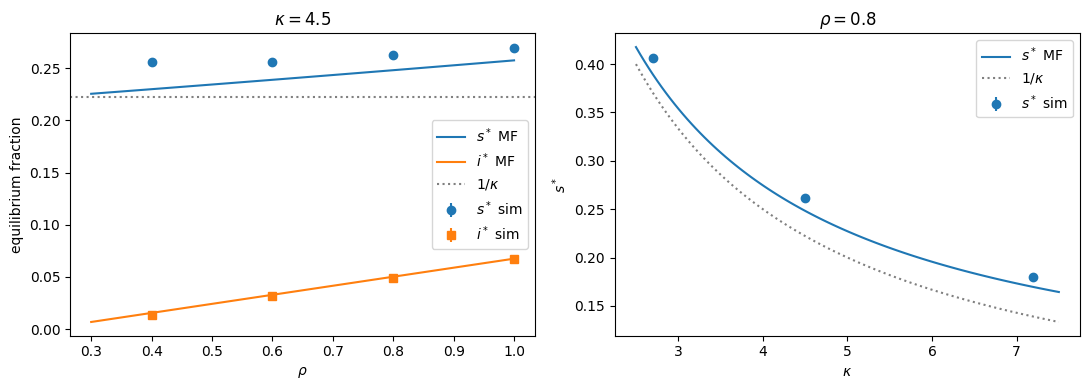

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

rr = np.linspace(0.3, 1.0, 100)
ax[0].errorbar(rho_sweep, res_rho[:, 0], yerr=res_rho[:, 1], fmt='o', label='$s^*$ sim')
ax[0].errorbar(rho_sweep, res_rho[:, 2], yerr=res_rho[:, 3], fmt='s', label='$i^*$ sim')
ax[0].plot(rr, [fixed_point(r, kappa, p_reg)[0] for r in rr], 'C0-',  label='$s^*$ MF')
ax[0].plot(rr, [fixed_point(r, kappa, p_reg)[1] for r in rr], 'C1-',  label='$i^*$ MF')
ax[0].axhline(1 / kappa, color='grey', ls=':', label=r'$1/\kappa$')
ax[0].set_xlabel(r'$\rho$'); ax[0].set_ylabel('equilibrium fraction')
ax[0].set_title(r'$\kappa = 4.5$'); ax[0].legend()

kk = np.linspace(2.5, 7.5, 100)
ax[1].errorbar(kap_sweep, res_kap[:, 0], yerr=res_kap[:, 1], fmt='o', label='$s^*$ sim')
ax[1].plot(kk, [fixed_point(rho_lt, k, p_reg)[0] for k in kk], 'C0-', label='$s^*$ MF')
ax[1].plot(kk, 1 / kk, color='grey', ls=':', label=r'$1/\kappa$')
ax[1].set_xlabel(r'$\kappa$'); ax[1].set_ylabel('$s^*$')
ax[1].set_title(fr'$\rho = {rho_lt}$'); ax[1].legend()

plt.tight_layout()
fig.savefig("regulation.png", dpi=200, bbox_inches='tight')
plt.show()

**The result:** (Error bars are the standard error over 3 runs, $\approx 0.001$, smaller than the markers.)

*Left.* As $\rho$ increases by a factor of $2.5$, the equilibrium firing fraction $i^*$ grows fivefold and matches the mean-field prediction across the whole range. The armed fraction $s^*$ stays almost constant ($0.256$–$0.270$). The extra traps are absorbed by the firing and spent populations, not the armed one. This is the regulation predicted in 5.1: the population consumes its resource down to the break-even level, independent of the supply.

*Right.* $s^*$ decreases with $\kappa$ and follows the exact mean-field fixed point. It does not follow the leading-order $1/\kappa$, and the difference between the two grows with $\kappa$: larger $\kappa$ means larger $i^*$, and so a larger correction from $s^* = i^*/(1 - e^{-\kappa i^*})$.

*Deviation.* The simulated $s^*$ lies systematically above mean-field: by $\approx 11\%$ at $\rho = 0.4$, falling to $\approx 5\%$ at $\rho = 1.0$. Because attempts are local, firing traps lose some of them to neighbours that are already spent, so the effective $\kappa$ is lower and more armed traps are needed to break even. The effect is strongest when traps are sparse. It is the same spatial correction seen in the invasion probability (5.3) and the persistence threshold (5.4).

## 5.6) **Stochastic extinction:** on a finite lattice a population that mean-field theory says should persist can die out by chance.

In mean-field theory $i(t)$ is a continuous fraction. It can become very small, but it never reaches zero, so any population with $\rho\kappa > 1$ and $p_{\text{regen}} > 0$ persists forever. On a lattice the population is a whole number of traps, $N_I(t) = L^2 i(t)$, and once $N_I = 0$ it can never recover: extinction is an **absorbing state**.

**When is extinction likely?** Section 5.4 showed that the first outbreak overshoots. It burns through the armed traps, and $i$ crashes to a deep minimum before re-arming can catch up. The danger is concentrated there. The natural predictor is the number of firing traps that mean-field theory says survive the first trough,
$$
N_{\min} = L^2 \min_{t > 10} i_{\text{MF}}(t).
$$
- If $N_{\min} \ll 1$, the trough holds less than one trap on average, so extinction is almost certain.
- If $N_{\min} \gg 1$, the trough is well populated and the chance of losing every trap is negligible.

This gives two predictions:
1. **System size matters.** At fixed parameters, $N_{\min} \propto L^2$, so persistence becomes more likely as the lattice grows. Mean-field theory is the limit $L \to \infty$ in which stochastic extinction disappears.
2. **Data collapse.** If $N_{\min}$ is the controlling variable, then runs at different $L$ and different $p_{\text{regen}}$ should all fall on a single curve $P_{\text{persist}}(N_{\min})$.

A simple model: if the number of traps surviving the trough is Poisson with mean $N_{\min}/N_0$, the population survives unless that number is zero, so
$$
P_{\text{persist}} \approx 1 - e^{-N_{\min}/N_0}.
$$
Here $N_0$ is a fitted scale that absorbs everything the mean-field trough misses (fluctuations in the depth of the trough, and the locality cost seen in 5.3–5.5).

**Measurement.** For $\rho = 0.8$, $\kappa = 4.5$, $p_{\text{regen}} \in \{0.03, 0.05, 0.08\}$ and $L \in \{25, 35, 50, 70\}$, simulate runs until 30 have **invaded** (survived past $t = 8$; early extinction was covered in 5.3). A run *persists* if it is still active at $T = 100$, well after the first trough.

In the following code cell, a function to count the number of troughts is coded and possible stochastic extinction is computed:

In [31]:
def sirs_meanfield(rho, kappa, p_regen, i0, steps):
    # Mean-field SIRS map. Returns array (steps+1, 3) of s, i, r fractions.
    s, i, r = rho - i0, i0, 0.0
    out = [(s, i, r)]
    for _ in range(steps):
        new = s * (1 - np.exp(-kappa * i))
        s, i, r = s - new + p_regen * r, new, r + i - p_regen * r
        out.append((s, i, r))
    return np.array(out)

In [ ]:
def trough_count(rho, kappa, p_regen, L, T=80, t_min=10):
    """Mean-field number of firing traps at the first trough."""
    mf = sirs_meanfield(rho, kappa, p_regen, i0=1 / L**2, steps=T)
    return mf[t_min:, 1].min() * L**2

p_ext_vals = [0.03, 0.05, 0.08]
L_ext_vals = [25, 35, 50, 70]
n_inv, T_ext, t_inv = 30, 100, 8
rng = np.random.default_rng(56)

rows = []   # (p_regen, L, N_min, P_persist, s.e.)
for p in p_ext_vals:
    for L in L_ext_vals:
        persist, n = 0, 0
        while n < n_inv:
            h = regen_history(rho_lt, f_k, p_succ_long, p_long=p_long, m=m,
                              p_regen=p, L=L, steps=T_ext, rng=rng)
            if len(h) - 1 < t_inv:          # failed to invade: not counted
                continue
            n += 1
            persist += (len(h) == T_ext + 1) and np.any(h[-1] == 1)
        P = persist / n_inv
        Nmin = trough_count(rho_lt, kappa, p, L)
        rows.append((p, L, Nmin, P, np.sqrt(P * (1 - P) / n_inv)))
        print(f"p_regen={p:.2f}  L={L:3d}  N_min={Nmin:6.2f}  P(persist)={P:.2f}")
rows = np.array(rows)

# This takes over four minutes to run

p_regen=0.03  L= 25  N_min=  0.04  P(persist)=0.00
p_regen=0.03  L= 35  N_min=  0.09  P(persist)=0.10
p_regen=0.03  L= 50  N_min=  0.18  P(persist)=0.00
p_regen=0.03  L= 70  N_min=  0.35  P(persist)=0.13
p_regen=0.05  L= 25  N_min=  0.68  P(persist)=0.17
p_regen=0.05  L= 35  N_min=  1.35  P(persist)=0.47
p_regen=0.05  L= 50  N_min=  2.72  P(persist)=0.83
p_regen=0.05  L= 70  N_min=  5.41  P(persist)=0.93
p_regen=0.08  L= 25  N_min=  3.40  P(persist)=0.63
p_regen=0.08  L= 35  N_min=  6.76  P(persist)=0.93
p_regen=0.08  L= 50  N_min= 13.59  P(persist)=1.00
p_regen=0.08  L= 70  N_min= 27.24  P(persist)=1.00


We now fit $N_0$ in $P_{\text{persist}} = 1 - e^{-N_{\min}/N_0}$ and plot (**Left**) persistence probability against lattice size $L$ for each $p_{\text{regen}}$ and (**Right**) the same points against the mean-field trough count $N_{\min} = L^2 i_{\min}$, with the fitted curve $1 - e^{-N_{\min}/N_0}$. If $N_{\min}$ is the controlling variable, all points collapse onto one curve.

N0 = 2.34 ± 0.27


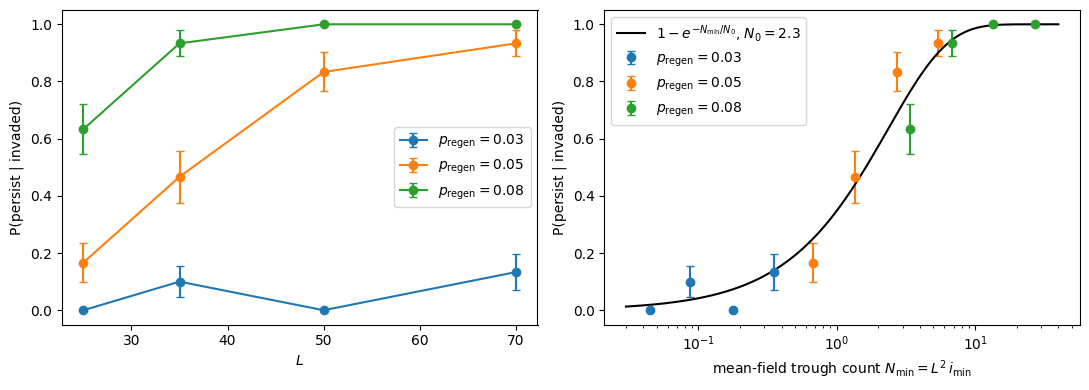

In [33]:
from scipy.optimize import curve_fit

model = lambda N, N0: 1 - np.exp(-N / N0)
sig = np.maximum(rows[:, 4], 0.03)                 # avoid zero error at P = 0 or 1
(N0,), cov = curve_fit(model, rows[:, 2], rows[:, 3], p0=[2], sigma=sig)
print(f"N0 = {N0:.2f} ± {np.sqrt(cov[0,0]):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for k, p in enumerate(p_ext_vals):                 # left: P vs L
    sel = rows[:, 0] == p
    ax[0].errorbar(rows[sel, 1], rows[sel, 3], yerr=rows[sel, 4], fmt='o-',
                   color=f'C{k}', capsize=3, label=fr'$p_{{\rm regen}}={p}$')
ax[0].set_xlabel('$L$'); ax[0].set_ylabel('P(persist | invaded)')
ax[0].set_ylim(-0.05, 1.05); ax[0].legend()

for k, p in enumerate(p_ext_vals):                 # right: collapse onto N_min
    sel = rows[:, 0] == p
    ax[1].errorbar(rows[sel, 2], rows[sel, 3], yerr=rows[sel, 4], fmt='o',
                   color=f'C{k}', capsize=3, label=fr'$p_{{\rm regen}}={p}$')
NN = np.geomspace(0.03, 40, 200)
ax[1].plot(NN, model(NN, N0), 'k-', label=fr'$1-e^{{-N_{{\min}}/N_0}}$, $N_0={N0:.1f}$')
ax[1].set_xscale('log')
ax[1].set_xlabel(r'mean-field trough count $N_{\min} = L^2\, i_{\min}$')
ax[1].set_ylabel('P(persist | invaded)'); ax[1].set_ylim(-0.05, 1.05); ax[1].legend()

plt.tight_layout()
fig.savefig("5.6.png", dpi=200, bbox_inches='tight')
plt.show()

**The result:**
- Left: for p_regen = 0.05 and 0.08, persistence rises steadily with L. The p_regen = 0.03 line wanders between 0 and 0.13 because its trough is far too deep at every L you tried (N_min < 0.4). Within its error bars it’s consistent with “almost always goes extinct”.


- Right: after re-plotting against N_min, the three colours, which had looked like three separate curves, line up along one sigmoid. Most points are within about 1σ of the fit.
Midpoint: P = 0.5 at N_min = N₀ ln 2 ≈ 1.6. A population needs the mean-field trough to hold about 1.6 firing traps to have an even chance of surviving.
Mild tension near N_min ≈ 3:
The orange point (L = 50) is about 2σ above the curve.
The green point (L = 25) is about 1.5σ below it.

    At similar N_min, the smaller lattice does worse. That could be noise, or an effect beyond N_min, such as boundaries mattering more at L = 25. An extnesion of teh work can be to try and find an explnation tot his, though this will not be attempted in this or any other notebooks in this repository.
    The blue zeros have no visible error bars because the binomial error is zero at P = 0. 

## 5.7) **Conclusion:** 
Adding a single parameter, the re-arming rate $p_{\text{regen}}$, turns the mousetrap cascade into a population model: a spatial, stochastic SIRS system in which firing traps reproduce, consume a finite resource and die, and the resource renews. The four questions set in 5.1 have the following answers.

| Question | Mean-field prediction | Lattice result |
|---|---|---|
| **Invasion** (5.3) | possible iff $\rho\kappa > 1$; probability $q$ from the branching process | threshold confirmed at $\rho = 1/\kappa$; $q$ follows the Binomial($m$) branching curve away from threshold, falls below it just above |
| **Long-term state** (5.4) | stable fixed point, approached through damped oscillations | stationary oscillations at the mean-field period; amplitude $\propto L^{b}$ with $b = -1.00 \pm 0.13$, so they are noise-sustained quasi-cycles, not a limit cycle |
| **Regulation** (5.5) | $s^*$ independent of $\rho$, $s^* \approx 1/\kappa$ | $s^*$ nearly constant over a 2.5-fold change in $\rho$; $i^*$ matches mean-field; $s^*$ follows the exact fixed point in $\kappa$ |
| **Stochastic extinction** (5.6) | none: populations with $\rho\kappa > 1$ always persist | persistence depends on lattice size; all runs collapse onto $P = 1 - e^{-N_{\min}/N_0}$, $N_0 = 2.3$ |

**What mean-field theory gets right.** The thresholds ($\rho\kappa = 1$), the equilibrium values ($s^*$, $i^*$), the oscillation frequency and the structure of the dynamics (invasion, overshoot, damped return to equilibrium) are all predicted correctly by the deterministic map, which is built on the same Poisson argument as the final-size equation of Notebook 3.

**What it misses:** Two effects appear in every section:

1. **Demographic noise.** A finite lattice holds a whole number of traps. This produces failed invasions above threshold (5.3), oscillations that never die out (5.4) and extinction in the first trough (5.6). All three vanish as $L \to \infty$, which is the limit in which mean-field theory becomes exact.
2. **Locality.** Attempts land near the firing trap, where neighbours are often already spent. This lowers the effective $\kappa$: invasion is less likely just above threshold (5.3), the equilibrium needs 5–11% more armed traps than predicted (5.5), and the real trough is deeper than the mean-field one ($N_0 > 1$, 5.6). It is the same mechanism as the onset offset in Notebook 3 and the mean-field failure in 1D in Notebook 4.

**In statistical-mechanics terms**, the model shows a non-equilibrium phase transition with an absorbing state (extinction), a mean-field theory that captures the averages but not the fluctuations, and finite-size effects that disappear only in the thermodynamic limit.

**Limitations.**
- One supercritical parameter set ($\kappa = 4.5$, $\rho = 0.8$) was studied in depth.
- Sample sizes are small: 3 runs per $L$ in 5.4, 30 per point in 5.6.
- Lattice sizes span only a factor of about 3.
- Only extinction in the first trough was measured, not the much slower extinction from the endemic state.
- The locality explanation is consistent with every result but was not tested directly.

**Next steps.**
1. Test locality directly: draw attempt targets uniformly over the whole lattice. Mean-field predictions should then become exact up to finite-size noise.
2. Repeat 5.4–5.6 in 1D, where locality is strongest, but mean-field theory approximation not as accurate.
3. Measure the mean time to extinction from the endemic state at small $L$, and how it grows with $L$.
4. Replace $\kappa$ with a measured effective $\kappa_{\text{eff}}$ and check how much of each discrepancy it removes.